# Agent 개요 실습: 환불 가능 여부 문의를 루프로 처리하고 바퀴 한도 바꾸기

**이 노트북에서 할 일**

1. 환불할 수 있는지만 묻는 새 문의와, 실행 전에 예상한 도구 차례를 적습니다.
2. 01·03·04절 함수를 이은 조립 함수로 문의를 처리하고, 요청 수·입력 토큰·멈춘 까닭·구조를 한 줄로 봅니다.
3. 바퀴 한도 하나만 4에서 2로 바꿔 다시 실행하고, 두 실행을 한 표로 견줍니다.

**준비물** — 프로젝트 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
모델은 `gpt-5.4-mini`이고, 모델 요청은 루프의 바퀴마다 한 번 나갑니다.
교재 출력에서는 실행 1이 3번, 실행 2가 2번으로 모두 5번이었습니다.
바퀴 한도 때문에 노트북 전체에서 6번을 넘지 않습니다.
요금표로 어림한 예상 비용은 0.01달러 아래이고, 청구 금액이 아닙니다.

도구는 03절에서 만든 도구 흉내라 바깥 서비스를 부르지 않습니다.
읽는 자료 파일도 새로 쓰는 파일도 없습니다.
걸린 초는 기기와 네트워크, 실행 때에 따라 달라집니다.
교재 출력을 만든 실행에서는 노트북 전체가 약 6초 만에 끝났습니다.

**기준 버전** — 패키지는 `langchain` 1.4.0, `langchain-openai` 1.6.1, `python-dotenv` 1.2.3입니다.
실습 폴더 잠금과 같은 판입니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**실습 범위** — 이 절은 챕터 끝 실습 절이고 30분 안에 끝나는 분량입니다.
강사와 함께 첫 셀부터 차례로 실행하고, 따로 내는 과제는 없습니다.
01~05절에서 쓴 이름과 문법만 씁니다.

실습 폴더 `labs/part5/ch17-agent-overview`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 그림으로 초록 상자 새 문의 환불할 수 있는지만 물음에서 파란 상자 serve_inquiry 이 절의 조립 함수와 파란 상자 run_measured_loop 03절 루프 04절 재기를 지나 보라 상자 gpt-5.4-mini 다음 행동을 JSON 글로 고름과 파란 상자 stop_reason 03절 정지 조건에 닿고 거기서 점선 둘이 나와 멈출 까닭이 없으면 도구를 부르고 run_measured_loop로 되돌아가고 사람 확인이나 모델의 끝 선택이나 같은 도구를 다시 고름이면 파란 상자 count_steps total_of tool_names classify로 가며 run_measured_loop에서도 점선 하나가 바퀴를 다 쓰면 바퀴 한도로 같은 파란 상자에 닿고 거기서 맨 아래 초록 상자 실행 요약 한 줄로 가는 그림](attachment:06-1-루프-정지-조건-요청-세기의-조립.png)

위에서 아래로 읽습니다.
초록 새 문의가 파란 조립 함수와 루프를 지나 보라 모델에 닿고, 파란 정지 조건이 멈출지 정합니다.
멈출 까닭이 없으면 점선을 따라 루프로 되돌아가 다음 바퀴를 돕니다.
바퀴 한도 멈춤은 루프가 바퀴를 다 쓴 뒤라, 루프 상자에서 따로 점선이 나옵니다.
어느 쪽으로 멈추든 01·02·04절 함수가 세고 가른 값이 맨 아래 초록 실행 요약에 모입니다.
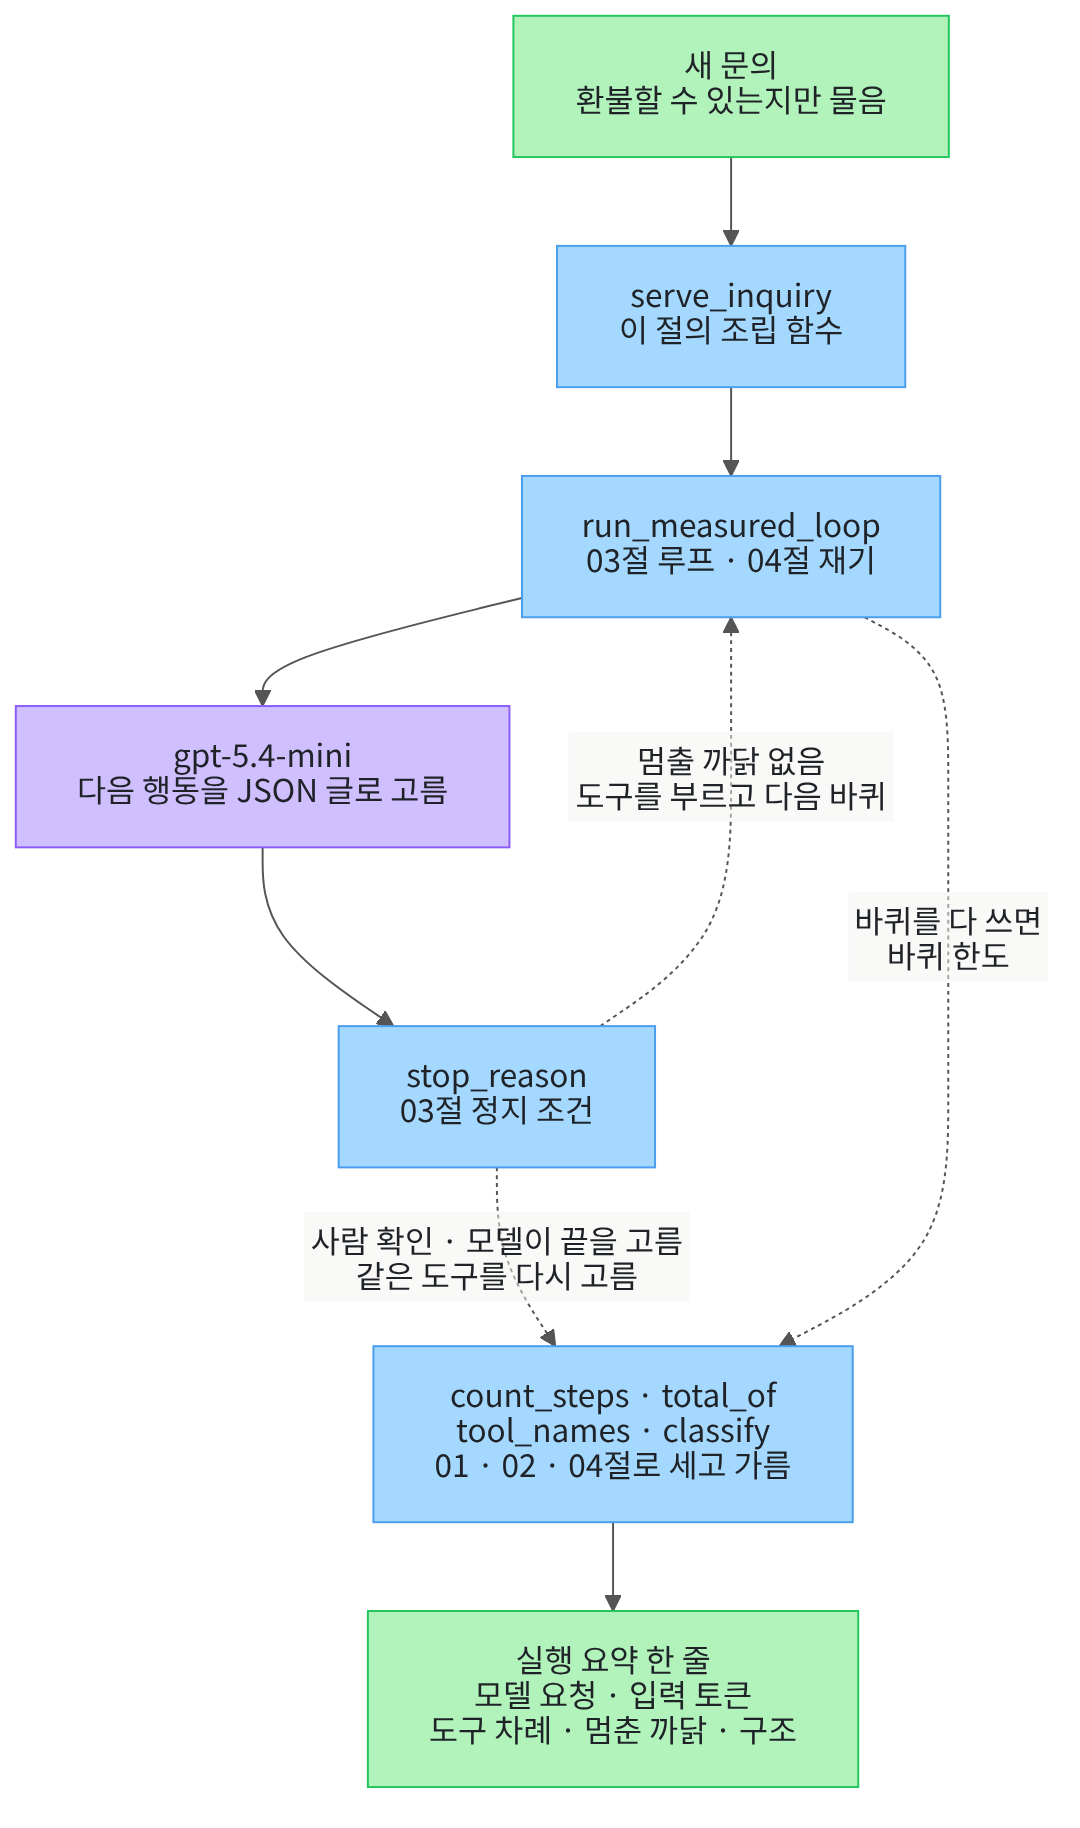

## 1. 준비

이번 절은 이 챕터의 실습입니다.
01~05절에서 쓴 이름과 문법만 쓰고 따로 내는 과제는 없습니다.
첫 셀은 패키지 세 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.1" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.


langchain: 1.4.0
langchain-openai: 1.6.1
python-dotenv: 1.2.3


**결과 읽기** — 설치가 끝나면 판 번호 세 줄이 보입니다.
출력 줄 `langchain: 1.4.0`과 `langchain-openai: 1.6.1`이 실습 폴더 잠금과 같은 판입니다.

다음 셀은 01~04절에서 배운 함수를 도구 파일에서 불러옵니다.
앞에서 배운 함수는 `agent_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다. 커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.

04절 함수 `run_measured_loop`·`print_measures`·`total_of`는 이 절에서 처음 도구 파일에서 가져옵니다.
04절 노트북과 같은 본문으로 옮겼고, 인자도 그대로입니다.
함수 `run_measured_loop`가 안에서 부르는 04절 함수 `choose_line`·`send_and_measure`도 함께 옮겼습니다.

In [2]:
# 모델 준비 함수와, 01~04절에서 배운 함수를 도구 파일에서 불러옵니다
from agent_tools import build_request, classify, count_steps, print_measures, print_results
from agent_tools import run_measured_loop, run_tool, tool_names, total_of, turn_lines
from langchain.chat_models import init_chat_model

print("01절:", "classify", "count_steps")
print("02절:", "tool_names")
print("03절:", "build_request", "print_results", "run_tool", "turn_lines")
print("04절:", "print_measures", "run_measured_loop", "total_of")

01절: classify count_steps
02절: tool_names
03절: build_request print_results run_tool turn_lines
04절: print_measures run_measured_loop total_of


**결과 읽기** — 출력 네 줄이 절마다 가져온 함수 이름입니다.
출력 줄 `01절: classify count_steps`의 두 함수로 기록을 세고 가릅니다.
출력 줄 `04절: print_measures run_measured_loop total_of`의 세 함수로 루프를 돌리며 요청마다 잽니다.
02절 함수 `tool_names`와 03절 함수 넷은 재료를 만들고 기록을 읽는 데 씁니다.

## 2. 키와 모델 준비

이 절도 03·04절과 같은 모델 `gpt-5.4-mini` 하나만 씁니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어도 모델이 고르는 행동이 매번 같다고 보장하지는 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-23에 이 모델로 실행한 결과입니다.

## 3. 상황과 재료

손님이 주문 A-1024를 지금 환불할 수 있는지 묻습니다.
환불해 달라는 글이 아니라, 할 수 있는지만 묻는 문의입니다.
03·04절의 환불 문의는 환불해 달라는 글이었습니다.
이 실습은 같은 도구 셋과 같은 머리글로 이 새 문의를 처리합니다.

다음 셀은 03절과 같은 도구 이름 셋과 사람 확인 도구, 머리글을 다시 적습니다.
환불 요청 등록은 02절에서 말한 부작용이 있는 도구라, 부르기 전에 사람이 확인합니다.

In [5]:
# 03절과 같은 도구 이름 셋·사람 확인 도구·바퀴마다 보낼 머리글을 다시 적습니다
tool_list = ["주문 조회", "환불 규정 확인", "환불 요청 등록"]
confirm_tools = ["환불 요청 등록"]
request_head = "손님 문의를 처리하고 있습니다. 다음에 부를 도구 하나를 고르세요.\n"
request_head = request_head + "쓸 수 있는 도구: " + ", ".join(tool_list) + "\n"
request_head = request_head + "더 부를 도구가 없으면 끝을 고르세요.\n"
request_head = request_head + 'JSON만 출력하세요: {"다음": "도구 이름 또는 끝", "까닭": "한 문장"}'
print("사람 확인이 필요한 도구:", confirm_tools)
print("머리글:")
print(request_head)

사람 확인이 필요한 도구: ['환불 요청 등록']
머리글:
손님 문의를 처리하고 있습니다. 다음에 부를 도구 하나를 고르세요.
쓸 수 있는 도구: 주문 조회, 환불 규정 확인, 환불 요청 등록
더 부를 도구가 없으면 끝을 고르세요.
JSON만 출력하세요: {"다음": "도구 이름 또는 끝", "까닭": "한 문장"}


**결과 읽기** — 출력 줄 `사람 확인이 필요한 도구: ['환불 요청 등록']`이 03절 값 그대로입니다.
라벨 줄 `머리글:` 아래 네 줄도 03·04절 머리글과 같습니다.
둘째 줄에 도구 이름 셋이 모두 있어, 모델은 환불 요청 등록도 고를 수 있습니다.

다음 셀은 03절 도구 흉내를 이름마다 한 번씩 불러 결과 글을 봅니다.
도구 흉내는 정해 둔 결과 글을 내놓는 파이썬 함수이고, 모델을 부르지 않습니다.

In [6]:
# 03절 도구 흉내를 이름마다 한 번씩 불러 결과 글을 봅니다(모델 요청 없음)
print("도구 이름 | 결과")
for tool_name in tool_list:
    print(tool_name, "|", run_tool(tool_name))

도구 이름 | 결과
주문 조회 | 주문 A-1024 · 무선 이어폰 · 배송 완료 · 받은 지 5일
환불 규정 확인 | 받은 지 7일 안의 상품은 환불할 수 있음
환불 요청 등록 | 환불 요청을 등록함


**결과 읽기** — 라벨 줄 `도구 이름 | 결과` 아래 세 줄이 도구 흉내의 결과 글입니다.
출력 줄 `주문 조회 | 주문 A-1024 · 무선 이어폰 · 배송 완료 · 받은 지 5일`에서 받은 지 며칠인지 봅니다.
출력 줄 `환불 규정 확인 | 받은 지 7일 안의 상품은 환불할 수 있음`이 환불 기한입니다.
두 결과를 함께 보면 환불할 수 있는지 답할 수 있습니다.

다음 셀은 새 문의와, 실행 전에 예상한 도구 차례를 적습니다.
예상은 위 결과 글을 보고 이 절에서 정했습니다.
받은 날은 주문 조회로, 기한은 환불 규정 확인으로 알 수 있어 도구 둘이면 됩니다.

In [7]:
# 이 실습의 새 문의와, 실행 전에 예상한 도구 차례를 적습니다(둘 다 이 절에서 실행 전에 정한 값)
check_question = "주문 A-1024를 지금 환불할 수 있는지 알려 주세요."
expected_tools = ["주문 조회", "환불 규정 확인"]
print("새 문의:", check_question)
print("예상한 도구 차례:", expected_tools)
print("출처:", "이 절에서 실행 전에 적은 글과 예상")

새 문의: 주문 A-1024를 지금 환불할 수 있는지 알려 주세요.
예상한 도구 차례: ['주문 조회', '환불 규정 확인']
출처: 이 절에서 실행 전에 적은 글과 예상


**결과 읽기** — 출력 줄 `새 문의: 주문 A-1024를 지금 환불할 수 있는지 알려 주세요.`가 이 실습의 문의입니다.
출력 줄 `예상한 도구 차례: ['주문 조회', '환불 규정 확인']`이 실행 전에 적은 예상입니다.
출력 줄 `출처: 이 절에서 실행 전에 적은 글과 예상`처럼 둘 다 실제 손님 글이 아닙니다.

다음 셀은 첫 바퀴에 보낼 요청 글을 03절 함수 `build_request`로 미리 만듭니다.
아직 부른 도구가 없으니 기록은 빈 목록 `[]`입니다.

In [8]:
# 첫 바퀴에 보낼 요청 글을 03절 함수로 미리 만들어 봅니다(아직 모델을 부르지 않습니다)
first_request = build_request(request_head, check_question, [])
print("첫 바퀴 요청 글:")
print(first_request)

첫 바퀴 요청 글:
손님 문의를 처리하고 있습니다. 다음에 부를 도구 하나를 고르세요.
쓸 수 있는 도구: 주문 조회, 환불 규정 확인, 환불 요청 등록
더 부를 도구가 없으면 끝을 고르세요.
JSON만 출력하세요: {"다음": "도구 이름 또는 끝", "까닭": "한 문장"}

문의: 주문 A-1024를 지금 환불할 수 있는지 알려 주세요.
지금까지 부른 도구와 결과: 없음


**결과 읽기** — 라벨 줄 `첫 바퀴 요청 글:` 아래가 모델이 첫 바퀴에 받을 글 전체입니다.
머리글 네 줄 뒤에 출력 줄 `문의: 주문 A-1024를 지금 환불할 수 있는지 알려 주세요.`가 이어집니다.
마지막 줄 `지금까지 부른 도구와 결과: 없음`으로 첫 요청임을 알립니다.

다음 셀은 첫 바퀴에 모델이 주문 조회를 골랐다고 정하고, 그 바퀴의 기록 줄을 만듭니다.
03절 함수 `turn_lines`는 고른 줄과 도구를 부른 줄, 두 줄을 내놓습니다.
고른 이름은 이 절에서 정한 것이고, 모델에게 묻지 않습니다.

In [9]:
# 첫 바퀴에 주문 조회를 골랐다고 정하고, 03절 함수로 그 바퀴의 기록 줄을 만듭니다(모델 요청 없음)
imagined_steps = turn_lines("주문 조회", "")
print_results(imagined_steps)

번호 | 단계 | 한 쪽 | 고른 쪽 | 결과
0 | 다음 단계 고르기 | 모델 | 코드 | 주문 조회
1 | 주문 조회 | 도구 | 모델 | 주문 A-1024 · 무선 이어폰 · 배송 완료 · 받은 지 5일


**결과 읽기** — 라벨 줄 `번호 | 단계 | 한 쪽 | 고른 쪽 | 결과` 아래 두 줄이 한 바퀴의 기록입니다.
출력 줄 `0 | 다음 단계 고르기 | 모델 | 코드 | 주문 조회`가 고른 줄입니다.
출력 줄 `1 | 주문 조회 | 도구 | 모델 | 주문 A-1024 · 무선 이어폰 · 배송 완료 · 받은 지 5일`이 도구를 부른 줄입니다.

다음 셀은 이 기록으로 둘째 바퀴 요청 글을 만들고, 첫 바퀴 요청 글과 글자 수를 견줍니다.

In [10]:
# 그 기록으로 둘째 바퀴 요청 글을 만들고, 첫 바퀴 요청 글과 글자 수를 견줍니다(모델 요청 없음)
second_request = build_request(request_head, check_question, imagined_steps)
print("둘째 바퀴 요청 글:")
print(second_request)
print("글자 수 | 첫 바퀴", len(first_request), "| 둘째 바퀴", len(second_request))

둘째 바퀴 요청 글:
손님 문의를 처리하고 있습니다. 다음에 부를 도구 하나를 고르세요.
쓸 수 있는 도구: 주문 조회, 환불 규정 확인, 환불 요청 등록
더 부를 도구가 없으면 끝을 고르세요.
JSON만 출력하세요: {"다음": "도구 이름 또는 끝", "까닭": "한 문장"}

문의: 주문 A-1024를 지금 환불할 수 있는지 알려 주세요.
지금까지 부른 도구와 결과:
- 주문 조회: 주문 A-1024 · 무선 이어폰 · 배송 완료 · 받은 지 5일
글자 수 | 첫 바퀴 200 | 둘째 바퀴 243


**결과 읽기** — 라벨 줄 `둘째 바퀴 요청 글:` 아래 마지막 줄에 도구 결과 한 줄이 붙었습니다.
출력 줄 `- 주문 조회: 주문 A-1024 · 무선 이어폰 · 배송 완료 · 받은 지 5일`이 그 줄입니다.
출력 줄 `글자 수 | 첫 바퀴 200 | 둘째 바퀴 243`처럼 바퀴가 늘면 요청 글이 길어집니다.
04절에서 보았듯 요청 글이 길어지면 입력 토큰도 늡니다.

## 4. 기록 장치와 조립 함수

기록을 보는 함수는 앞 절에서 이미 셋 만들었습니다.
03절 함수 `print_results`는 기록을 줄마다 출력합니다.
04절 함수 `print_measures`는 바퀴마다 잰 값을, `total_of`는 모델이 한 줄의 칸 값 합을 냅니다.

다음 셀은 이 실습의 기록 장치입니다.
실행 요약 여러 개를 받아, 실행마다 한 줄로 출력합니다.
한 줄에는 바퀴 한도, 모델 요청 수, 입력 토큰 합, 도구 차례, 멈춘 까닭, 구조가 들어갑니다.
출력 토큰과 걸린 초는 04절에서 실행마다 달라졌으므로 요약에 넣지 않습니다.

In [11]:
# 기록 장치: 실행 요약을 실행마다 한 줄로 출력합니다(바퀴 한도·모델 요청·입력 토큰·도구 차례·멈춘 까닭·구조)
def print_reports(reports):
    print("바퀴 한도 | 모델 요청 | 입력 토큰 | 도구 차례 | 멈춘 까닭 | 구조")
    for report in reports:
        print(report["바퀴 한도"], "|", report["모델 요청"], "|", report["입력 토큰"], "|",
              report["도구 차례"], "|", report["멈춘 까닭"], "|", report["구조"])

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `print_reports`는 실행 요약 딕셔너리의 목록을 받습니다.
라벨 줄을 먼저 출력하고, 요약 하나마다 한 줄씩 출력합니다.

다음 셀은 이 실습의 조립 함수입니다.
03절 루프를 04절처럼 재며 돌리고, 그 기록을 세고 가른 값을 딕셔너리 하나에 모읍니다.
함수 안 주석에 어느 절에서 배운 일인지 적었습니다.

모델 요청 수는 칸 「한 쪽」이 모델인 줄 수로 셉니다.
02절에서 정한 약속이고, 03·04절에서 실제로 그 줄마다 요청이 한 번 나갔습니다.
멈춘 까닭은 기록 마지막 줄 `steps[-1]`의 칸 「결과」에서 꺼냅니다.

In [12]:
# 조립 함수: 문의 하나를 03절 루프로 처리하며 04절처럼 재고, 세고 가른 값을 실행 요약 하나에 모읍니다
def serve_inquiry(chat_model, head, question, confirm_tools, turn_limit):
    # 03·04절: 모델이 다음 행동을 고르고 코드가 멈출지 정하는 루프(요청마다 잰 값이 기록에 남습니다)
    steps = run_measured_loop(chat_model, head, question, confirm_tools, turn_limit)
    report = {"바퀴 한도": turn_limit, "기록": steps}
    # 01·04절: 모델 요청 수(칸 「한 쪽」이 모델인 줄 수)와 입력 토큰 합
    report["모델 요청"] = count_steps(steps, "한 쪽", "모델")
    report["입력 토큰"] = total_of(steps, "입력 토큰")
    # 02·03절: 부른 도구 차례와 멈춘 까닭(마지막 멈춤 줄), 01절: 구조
    report["도구 차례"] = tool_names(steps)
    report["멈춘 까닭"] = steps[-1]["결과"]
    report["구조"] = classify(steps)
    return report

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `serve_inquiry`는 모델, 머리글, 문의, 사람 확인 도구 목록, 바퀴 한도를 인자로 받습니다.
04절 함수 `run_measured_loop`와 인자가 같고, 내놓는 값이 실행 요약 딕셔너리입니다.
이 함수를 한 번 부르면 모델 요청이 바퀴 한도만큼까지 나갑니다.

## 5. 실행 1 · 바퀴 한도 4

실행 1은 03·04절과 같은 바퀴 한도 4로 새 문의를 처리합니다.
사람 확인 도구는 환불 요청 등록 하나 그대로입니다.

실행 전에 예상해 봅니다.
첫 두 바퀴에는 3절에서 적은 예상대로 주문 조회와 환불 규정 확인을 고를 것입니다.
문의는 환불할 수 있는지만 물으니, 문의만 보면 셋째 바퀴에는 끝을 고르면 됩니다.
셋째 바퀴에 무엇을 고르든 모델 요청은 세 번일 것입니다.

In [13]:
# 실행 1: 바퀴 한도 4로 새 문의를 처리합니다(바퀴마다 모델 요청 1번, 네 번까지)
turn_limit = 4
report_one = serve_inquiry(model, request_head, check_question, confirm_tools, turn_limit)
print_results(report_one["기록"])

번호 | 단계 | 한 쪽 | 고른 쪽 | 결과
0 | 다음 단계 고르기 | 모델 | 코드 | 주문 조회
1 | 주문 조회 | 도구 | 모델 | 주문 A-1024 · 무선 이어폰 · 배송 완료 · 받은 지 5일
2 | 다음 단계 고르기 | 모델 | 코드 | 환불 규정 확인
3 | 환불 규정 확인 | 도구 | 모델 | 받은 지 7일 안의 상품은 환불할 수 있음
4 | 다음 단계 고르기 | 모델 | 코드 | 환불 요청 등록
5 | 멈춤 | 코드 | 코드 | 사람 확인


**결과 읽기** — 라벨 줄 아래 여섯 줄이 실행 1의 기록입니다.
출력 줄 `4 | 다음 단계 고르기 | 모델 | 코드 | 환불 요청 등록`에서 셋째 바퀴에 등록을 골랐습니다.
마지막 줄 `5 | 멈춤 | 코드 | 코드 | 사람 확인`에서 코드가 부르기 전에 멈췄습니다.
첫 두 바퀴는 예상대로 주문 조회와 환불 규정 확인이었습니다.

문의는 환불할 수 있는지만 물었는데, 모델은 등록까지 고르려 했습니다.
사람 확인 목록에 이 도구가 없었다면 코드는 그대로 불렀을 것입니다. 03절 10절에서 본 모습입니다.
이 도구는 흉내라 불러도 실제로 바뀌는 것은 없습니다.
노트북을 실행하기 전에 노트북 밖에서 같은 루프를 다섯 번 돌렸을 때도 셋째 바퀴는 모두 등록이었습니다.

In [14]:
# 실행 1에서 바퀴마다 고른 이름과 잰 값을 봅니다(04절 함수, 요청 없음)
print_measures(report_one["기록"])
print("바퀴 수:", report_one["모델 요청"])

바퀴 | 고른 이름 | 입력 토큰 | 출력 토큰 | 걸린 초
1 | 주문 조회 | 116 | 40 | 0.943
2 | 환불 규정 확인 | 138 | 50 | 1.009
3 | 환불 요청 등록 | 160 | 52 | 0.927
바퀴 수: 3


**결과 읽기** — 라벨 줄 `바퀴 | 고른 이름 | 입력 토큰 | 출력 토큰 | 걸린 초` 아래 세 줄이 바퀴마다 잰 값입니다.
출력 줄 `1 | 주문 조회 | 116`, `2 | 환불 규정 확인 | 138`, `3 | 환불 요청 등록 | 160`으로 시작합니다.
입력 토큰은 바퀴마다 늘었고, 출력 줄 `바퀴 수: 3`처럼 모델 요청은 세 번이었습니다.

출력 토큰과 걸린 초는 실행마다 달라집니다.
그래서 이 실습은 두 값을 결론에 쓰지 않습니다.

In [15]:
# 실행 1의 요약을 한 줄로 보고, 실행 전 예상과 견줍니다(요청 없음)
print_reports([report_one])
print("예상한 도구 차례와 같은가:", report_one["도구 차례"] == expected_tools)
print("환불 요청 등록을 부른 줄 수:", count_steps(report_one["기록"], "단계", "환불 요청 등록"))

바퀴 한도 | 모델 요청 | 입력 토큰 | 도구 차례 | 멈춘 까닭 | 구조
4 | 3 | 414 | ['주문 조회', '환불 규정 확인'] | 사람 확인 | 에이전트 후보
예상한 도구 차례와 같은가: True
환불 요청 등록을 부른 줄 수: 0


**결과 읽기** — 라벨 줄 아래 한 줄이 실행 1의 요약입니다.
출력 줄 `4 | 3 | 414 | ['주문 조회', '환불 규정 확인'] | 사람 확인 | 에이전트 후보`를 봅니다.
출력 줄 `예상한 도구 차례와 같은가: True`로 부른 도구는 예상과 같았습니다.
출력 줄 `환불 요청 등록을 부른 줄 수: 0`으로 등록 도구는 한 번도 불리지 않았습니다.

구조가 에이전트 후보인 까닭은 01절 규칙 그대로입니다.
모델이 고른 도구가 실제로 불린 줄이 있기 때문입니다.

## 6. 실행 2 · 바퀴 한도 2

바꿀 값은 바퀴 한도 하나입니다. 4에서 2로 낮춥니다.
문의와 머리글, 사람 확인 도구 목록, 조립 함수는 실행 1과 같습니다.

실행 전에 예상해 봅니다.
첫 두 바퀴는 실행 1과 요청 글이 같으니 같은 두 도구를 고를 것입니다.
셋째 바퀴가 오기 전에 바퀴 한도로 멈추고, 모델 요청은 두 번일 것입니다.
실행 1에서 모델이 등록을 고른 셋째 요청은 보내지 않을 것입니다.

In [16]:
# 실행 2: 바꿀 값은 바퀴 한도 하나입니다. 4 대신 2로 같은 문의를 처리합니다(모델 요청 두 번까지)
short_limit = 2
report_two = serve_inquiry(model, request_head, check_question, confirm_tools, short_limit)
print_results(report_two["기록"])

번호 | 단계 | 한 쪽 | 고른 쪽 | 결과
0 | 다음 단계 고르기 | 모델 | 코드 | 주문 조회
1 | 주문 조회 | 도구 | 모델 | 주문 A-1024 · 무선 이어폰 · 배송 완료 · 받은 지 5일
2 | 다음 단계 고르기 | 모델 | 코드 | 환불 규정 확인
3 | 환불 규정 확인 | 도구 | 모델 | 받은 지 7일 안의 상품은 환불할 수 있음
4 | 멈춤 | 코드 | 코드 | 바퀴 한도


**결과 읽기** — 라벨 줄 아래 다섯 줄이 실행 2의 기록입니다.
출력 줄 `3 | 환불 규정 확인 | 도구 | 모델 | 받은 지 7일 안의 상품은 환불할 수 있음`까지 두 도구를 불렀습니다.
마지막 줄 `4 | 멈춤 | 코드 | 코드 | 바퀴 한도`에서 코드가 바퀴 한도로 멈췄습니다.
예상과 맞았습니다.

In [17]:
# 실행 2에서 바퀴마다 고른 이름과 잰 값을 봅니다(요청 없음)
print_measures(report_two["기록"])
print("바퀴 수:", report_two["모델 요청"])

바퀴 | 고른 이름 | 입력 토큰 | 출력 토큰 | 걸린 초
1 | 주문 조회 | 116 | 40 | 0.722
2 | 환불 규정 확인 | 138 | 45 | 0.857
바퀴 수: 2


**결과 읽기** — 라벨 줄 아래 두 줄이 바퀴마다 잰 값입니다.
출력 줄 `1 | 주문 조회 | 116`과 `2 | 환불 규정 확인 | 138`의 입력 토큰이 실행 1 첫 두 바퀴와 같습니다.
출력 줄 `바퀴 수: 2`처럼 모델 요청은 두 번이었습니다.

출력 토큰과 걸린 초는 이번에도 결론에 쓰지 않습니다.

## 7. 두 실행 견주기

다음 셀은 두 실행의 요약을 한 표로 견주고, 부른 도구 차례가 같은지 봅니다.

In [18]:
# 두 실행의 요약을 한 표로 견주고, 부른 도구 차례가 같은지 봅니다
print_reports([report_one, report_two])
print("부른 도구 차례가 같은가:", report_one["도구 차례"] == report_two["도구 차례"])

바퀴 한도 | 모델 요청 | 입력 토큰 | 도구 차례 | 멈춘 까닭 | 구조
4 | 3 | 414 | ['주문 조회', '환불 규정 확인'] | 사람 확인 | 에이전트 후보
2 | 2 | 254 | ['주문 조회', '환불 규정 확인'] | 바퀴 한도 | 에이전트 후보
부른 도구 차례가 같은가: True


**결과 읽기** — 라벨 줄 아래 두 줄을 견줍니다.
출력 줄 `4 | 3 | 414 |`로 시작하는 줄이 실행 1, `2 | 2 | 254 |`로 시작하는 줄이 실행 2입니다.
출력 줄 `부른 도구 차례가 같은가: True`로 두 실행이 부른 도구는 같았습니다.
두 실행 모두 코드가 멈췄고, 까닭은 사람 확인과 바퀴 한도로 달랐습니다.

다음 셀은 두 실행의 첫 바퀴 입력 토큰을 나란히 봅니다.
첫 바퀴 요청 글은 두 실행이 글자까지 같습니다.
기록 첫 줄 `[0]`은 늘 첫 바퀴의 고른 줄입니다.

In [19]:
# 두 실행의 첫 바퀴 요청은 요청 글이 같습니다: 입력 토큰을 나란히 봅니다
first_one = report_one["기록"][0]
first_two = report_two["기록"][0]
print("첫 바퀴 | 실행 1", first_one["입력 토큰"], "| 실행 2", first_two["입력 토큰"])
print("첫 바퀴 입력 토큰이 같은가:", first_one["입력 토큰"] == first_two["입력 토큰"])

첫 바퀴 | 실행 1 116 | 실행 2 116
첫 바퀴 입력 토큰이 같은가: True


**결과 읽기** — 출력 줄 `첫 바퀴 | 실행 1 116 | 실행 2 116`에서 두 실행의 첫 요청 입력 토큰이 같습니다.
출력 줄 `첫 바퀴 입력 토큰이 같은가: True`입니다.
04절에서 본 것처럼 요청 글이 같으면 입력 토큰도 같았습니다.

다음 셀은 실행 2가 보내지 않은 요청을 찾습니다.
실행 1 기록에서 끝에서 둘째 줄 `[-2]`는 멈춤 줄 바로 앞, 마지막 바퀴의 고른 줄입니다.

In [20]:
# 실행 2가 보내지 않은 요청을 봅니다: 실행 1의 마지막 고른 줄(멈춤 줄 바로 앞 줄)
last_choice = report_one["기록"][-2]
saved_tokens = report_one["입력 토큰"] - report_two["입력 토큰"]
print("실행 1 마지막 바퀴 | 고른 이름", last_choice["결과"], "| 입력 토큰", last_choice["입력 토큰"])
print("줄어든 모델 요청:", report_one["모델 요청"] - report_two["모델 요청"])
print("줄어든 입력 토큰:", saved_tokens)
print("마지막 바퀴 입력 토큰과 같은가:", saved_tokens == last_choice["입력 토큰"])

실행 1 마지막 바퀴 | 고른 이름 환불 요청 등록 | 입력 토큰 160
줄어든 모델 요청: 1
줄어든 입력 토큰: 160
마지막 바퀴 입력 토큰과 같은가: True


**결과 읽기** — 출력 줄 `실행 1 마지막 바퀴 | 고른 이름 환불 요청 등록 | 입력 토큰 160`이 그 요청입니다.
출력 줄 `줄어든 모델 요청: 1`과 `줄어든 입력 토큰: 160`을 봅니다.
출력 줄 `마지막 바퀴 입력 토큰과 같은가: True`로 줄어든 몫이 그 요청 하나의 몫과 같습니다.

바퀴 한도 2는 모델이 등록을 고른 바퀴가 오기 전에 루프를 멈췄습니다.
그만큼 요청 하나와, 요청 글이 가장 긴 바퀴의 입력 토큰을 쓰지 않았습니다.

다음 셀은 두 기록을 01절 규칙으로 다시 봅니다.

In [21]:
# 01절 규칙으로 두 기록을 다시 봅니다: 모델이 고른 단계 수와 멈춤 줄의 고른 쪽
print("바퀴 한도 | 모델이 고른 단계 수 | 멈춤 줄 고른 쪽 | 구조")
for report in [report_one, report_two]:
    steps = report["기록"]
    chosen = count_steps(steps, "고른 쪽", "모델")
    print(report["바퀴 한도"], "|", chosen, "|", steps[-1]["고른 쪽"], "|", report["구조"])

바퀴 한도 | 모델이 고른 단계 수 | 멈춤 줄 고른 쪽 | 구조
4 | 2 | 코드 | 에이전트 후보
2 | 2 | 코드 | 에이전트 후보


**결과 읽기** — 라벨 줄 아래 두 줄이 두 기록을 01절 규칙으로 본 값입니다.
출력 줄 `4 | 2 | 코드 | 에이전트 후보`와 `2 | 2 | 코드 | 에이전트 후보`가 같습니다.
두 기록 모두 모델이 고른 도구 두 단계가 불려 에이전트 후보입니다.
멈춤 줄의 고른 쪽은 두 기록 모두 코드이고, 모델이 끝을 고른 기록은 없습니다.

그래서 기록만 보고는 일을 다 했는지 코드가 알 수 없습니다.
이번에는 3절에서 적은 예상과 견주어, 필요한 두 도구가 불렸음을 알았습니다.

## 정리

1. 01·03·04절 함수를 조립 함수 하나로 이어, 새 문의의 요청 수·입력 토큰·멈춘 까닭·구조를 한 줄로 보았습니다.
2. 환불할 수 있는지만 물었는데 모델은 셋째 바퀴에 환불 요청 등록을 골랐고, 사람 확인이 부르기 전에 멈췄습니다.
3. 바퀴 한도를 2로 낮추자 같은 두 도구를 부른 뒤 코드가 멈췄습니다. 모델 요청은 3번에서 2번, 입력 토큰 합은 414에서 254로 줄었습니다.

이 절로 Ch 17이 끝납니다.
Ch 18에서는 워크플로우 다섯 패턴을 프레임워크 없이 만듭니다.